# Paso 19 · Historia, panorama y bibliografía

Notebook del **Paso 19**: el paso de cierre es de lectura, pero también se puede *programar*: una cronología dibujada, el mapa «paso del método ↔ paso del curso ↔ función de `qftlib`» **comprobado por código**, un glosario con autoevaluación y la lista de lo cubierto y lo pendiente.

> **Honestidad.** El panorama histórico es el del artículo de García-Sanz (RIAI 2005, 2(3), 25–38); no incluye lo posterior. No se usa ninguna toolbox QFT de terceros y los datos del caso real del Paso 12 son sintéticos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
import os, glob
from nbhelp import RAIZ, AZUL, NARANJA, TINTA, GRIS
import qftlib as q

## 1. Cronología de una idea

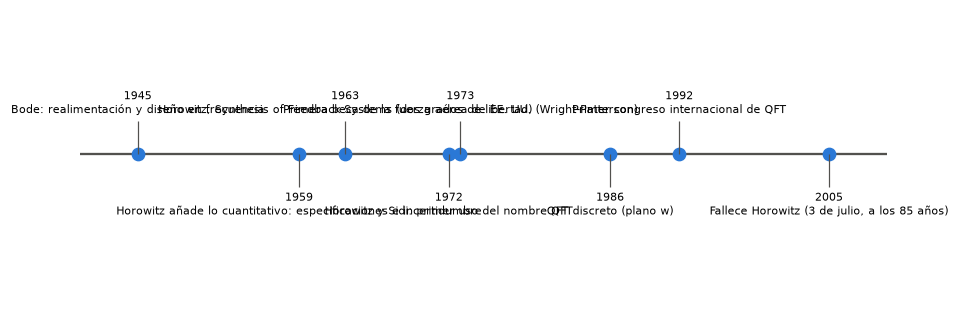

La decisión de fondo, ya en 1959: el lazo abierto L = P·G es la herramienta de diseño y el problema es la incertidumbre de la planta.


In [3]:
hitos = [(1945, "Bode: realimentación y diseño en frecuencia"),
         (1959, "Horowitz añade lo cuantitativo: especificaciones e incertidumbre"),
         (1963, "Horowitz, Synthesis of Feedback Systems (dos grados de libertad)"),
         (1972, "Horowitz y Sidi: primer uso del nombre QFT"),
         (1973, "Primera beca de la fuerza aérea de EE. UU. (Wright-Patterson)"),
         (1986, "QFT discreto (plano w)"),
         (1992, "Primer congreso internacional de QFT"),
         (2005, "Fallece Horowitz (3 de julio, a los 85 años)")]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hlines(0, 1940, 2010, color=GRIS, lw=1.5)
for i, (a, t) in enumerate(hitos):
    y = 1 if i % 2 == 0 else -1
    ax.plot(a, 0, "o", color=AZUL, ms=8); ax.vlines(a, 0, 0.55*y, color=GRIS, lw=0.8)
    ax.text(a, 0.62*y, f"{a}\n{t}", ha="center", va="bottom" if y > 0 else "top", fontsize=7.2)
ax.set_ylim(-2.4, 2.4); ax.set_xlim(1938, 2012); ax.axis("off"); plt.show()
print("La decisión de fondo, ya en 1959: el lazo abierto L = P·G es la herramienta de diseño y el problema es la incertidumbre de la planta.")

## 2. La idea central en tres frases

QFT usa la realimentación para **reducir a la vez** el efecto de la incertidumbre y cumplir las especificaciones, con el controlador más simple y el menor ancho de banda. La realimentación solo hace falta si hay incertidumbre o perturbaciones no medidas. Especificaciones e incertidumbre se condensan en *bounds* sobre Nichols y el diseño se hace con **una sola planta** (la nominal).

## 3. Los seis pasos del método, comprobados en el código

Cada paso del método tiene su paso del curso y su función en la biblioteca. La celda lo **verifica** (si cambias `qftlib.py` y renombras algo, esto avisa):

In [4]:
metodo = [("Modelo, plantillas y planta nominal", "paso 7",        ["plant_family", "template", "boundary_indices"]),
          ("Definición de especificaciones",      "paso 8",        ["spec_stability", "spec_tracking", "spec_disturbance", "spec_noise"]),
          ("Creación de contornos (bounds)",      "paso 8 y 16",   ["allowed_map", "quad_stability", "exact_forbidden"]),
          ("Síntesis del controlador G",          "paso 9 y 17",   ["margin_db", "check_L0", "shape_de", "synthesize_refine"]),
          ("Síntesis del prefiltro F",            "paso 9",        ["prefilter_search"]),
          ("Validación (frecuencia, tiempo)",     "pasos 9 y 12",  ["verify"])]
print(f"{'Paso del método (García-Sanz, 2005)':<40}{'En el curso':<14}función(es) de qftlib")
for nombre, paso, fns in metodo:
    assert all(hasattr(q, f) for f in fns), f"falta alguna función de {fns}"
    print(f"{nombre:<40}{paso:<14}{', '.join(fns)}")
print("\nTodas las funciones existen en qftlib.")

Paso del método (García-Sanz, 2005)     En el curso   función(es) de qftlib
Modelo, plantillas y planta nominal     paso 7        plant_family, template, boundary_indices
Definición de especificaciones          paso 8        spec_stability, spec_tracking, spec_disturbance, spec_noise
Creación de contornos (bounds)          paso 8 y 16   allowed_map, quad_stability, exact_forbidden
Síntesis del controlador G              paso 9 y 17   margin_db, check_L0, shape_de, synthesize_refine
Síntesis del prefiltro F                paso 9        prefilter_search
Validación (frecuencia, tiempo)         pasos 9 y 12  verify

Todas las funciones existen en qftlib.


El diagrama de flujo del método incluye **bucles de reajuste**: si no hay solución se revisa el modelo; si la verificación falla se reajusta el diseño (nuestro «bucle de refinado» del Paso 16). QFT es riguroso solo en frecuencia: las especificaciones temporales se *traducen* antes y se comprueban en tiempo con las peores plantas.

## 4. Cómo se calculan los bounds: la línea de trabajo

- Antes: trabajo **gráfico manual** sobre Nichols.
- Chait y Yaniv (1993), Rodrigues, Chait y Yaniv (1997): las especificaciones se convierten en **inecuaciones cuadráticas** $a g^2+bg+c\ge0$: es el algoritmo exacto del Paso 16 (`quad_*`, `exact_forbidden`).
- Otros: Zhao y Jayasuriya (1994), Moreno y otros (1997), Nataraj y Sardar (2000), Nataraj (2002). Templates: Bartlett (1993), Gutman y otros (1994).

> Nomenclatura: en el artículo la ganancia incógnita se llama $g$ y la fase $\varphi$; aquí $x=|L_0|$ porque $P_0$ está incluida en $L_0$. Es el mismo resultado.

## 5. Las ramas de investigación (hasta 2005) y qué cubre este curso

In [5]:
ramas = [("Fase no mínima",               "desplazar los bounds; Horowitz y Sidi (1978), Horowitz y Liao (1984)", "nota en el paso 12"),
         ("Sistemas discretos",           "plano w; Horowitz (1986)",                                              "pasos 10-12"),
         ("No lineales / LTV",            "reducción a problemas LTI; Horowitz (1976-1983)",                       "paso 15"),
         ("Grandes retardos",             "estructura tipo Smith; García-Sanz y Guillén (1999)",                   "no cubierto"),
         ("MIMO",                         "n problemas MISO en secuencia; Horowitz (1979-82)",                     "no cubierto"),
         ("Parámetros distribuidos",      "transformada múltiple de Laplace; Horowitz y Azor (1983)",              "no cubierto"),
         ("Cascada y reparto de cargas",  "Horowitz y otros (1985); Eitelberg (1999)",                             "paso 14 (cascada)"),
         ("LTV por tramos",               "conmutación; Yaniv y Boneh (1997)",                                     "no cubierto")]
print(f"{'Rama':<30}{'Idea principal':<72}{'En este curso'}")
for r_, i_, c_ in ramas: print(f"{r_:<30}{i_:<72}{c_}")
print(f"\ncubiertas (total o parcialmente): {sum(c != 'no cubierto' for _, _, c in ramas)} de {len(ramas)}")

Rama                          Idea principal                                                          En este curso
Fase no mínima                desplazar los bounds; Horowitz y Sidi (1978), Horowitz y Liao (1984)    nota en el paso 12
Sistemas discretos            plano w; Horowitz (1986)                                                pasos 10-12
No lineales / LTV             reducción a problemas LTI; Horowitz (1976-1983)                         paso 15
Grandes retardos              estructura tipo Smith; García-Sanz y Guillén (1999)                     no cubierto
MIMO                          n problemas MISO en secuencia; Horowitz (1979-82)                       no cubierto
Parámetros distribuidos       transformada múltiple de Laplace; Horowitz y Azor (1983)                no cubierto
Cascada y reparto de cargas   Horowitz y otros (1985); Eitelberg (1999)                               paso 14 (cascada)
LTV por tramos                conmutación; Yaniv y Boneh (1997)              

## 6. Aplicaciones documentadas y software

- **Aeronáutica y espacio**: vuelo MIMO, X-29 (inestable, fase no mínima), reabastecimiento en vuelo, F-16, UAV, alas flexibles, telescopios en satélite, satélites en formación.
- **Otros**: depuradora de fangos activos, aerogeneradores, redes eléctricas, robótica, motores, actuadores electrohidráulicos, suspensión activa, pasteurización, hornos, cancelación de ruido en telefonía.
- Las primeras aplicaciones reales (1982–1997) fueron aeronáuticas (Wright-Patterson). La lista procede del artículo de 2005.
- **Software (2005)**: QFT Toolbox (Borghesani, Chait, Yaniv), Qsyn (Gutman), el de la fuerza aérea (Houpis, Sating), herramientas de García-Sanz y otros, un programa sobre SysQuake. **Aquí**: ninguna; solo `qftlib.py` y `code/matlab/`. Hoy puede haber otras herramientas: conviene comprobarlo antes de depender de ellas.

## 7. Cubierto y por cubrir — comprobado contra el repositorio

Cuántos notebooks y diapositivas hay realmente:

In [6]:
nbs = sorted(glob.glob(os.path.join(RAIZ, "notebooks", "paso*.ipynb")))
print(f"notebooks: {len(nbs)} de 19")
for n in nbs: print("  ", os.path.basename(n))
cubierto = ["SISO continuo y digital", "Incertidumbre paramétrica (caja)", "Estabilidad, perturbación y seguimiento",
            "Loop shaping manual y automático", "Muestreo por eventos, cascada, no lineales simples", "Algoritmos y código (Python y MATLAB)"]
pendiente = ["MIMO completo y matriz no diagonal", "Parámetros distribuidos y LTV", "Incertidumbre no paramétrica (con cálculo)",
             "Esfuerzo de control (T4) y ruido (T3) con ejemplos", "Validación en prototipo", "Fase no mínima con bounds desplazados, con cálculo"]
print("\nCubierto :", *cubierto, sep="\n  - "); print("\nPor cubrir:", *pendiente, sep="\n  - ")
print("\nUn siguiente curso natural: MIMO por secuencia de problemas MISO.")

notebooks: 19 de 19
   paso01_numeros_complejos.ipynb
   paso02_funciones_transferencia.ipynb
   paso03_respuesta_frecuencia.ipynb
   paso04_decibelios_bode.ipynb
   paso05_realimentacion.ipynb
   paso06_nichols.ipynb
   paso07_templates.ipynb
   paso08_bounds.ipynb
   paso09_loop_shaping.ipynb
   paso10_digital.ipynb
   paso11_dos_caminos.ipynb
   paso12_estabilidad_limites.ipynb
   paso13_muestreo_eventos.ipynb
   paso14_dos_estados.ipynb
   paso15_no_lineales.ipynb
   paso16_algoritmos.ipynb
   paso17_python.ipynb
   paso18_matlab.ipynb
   paso19_historia.ipynb

Cubierto :
  - SISO continuo y digital
  - Incertidumbre paramétrica (caja)
  - Estabilidad, perturbación y seguimiento
  - Loop shaping manual y automático
  - Muestreo por eventos, cascada, no lineales simples
  - Algoritmos y código (Python y MATLAB)

Por cubrir:
  - MIMO completo y matriz no diagonal
  - Parámetros distribuidos y LTV
  - Incertidumbre no paramétrica (con cálculo)
  - Esfuerzo de control (T4) y ruido (T3)

## 8. Glosario con autoevaluación

In [7]:
glosario = {
 "Template": "conjunto de P(jω_i) de todas las plantas, en Nichols",
 "Bound / contorno": "frontera para L0(jω) que garantiza una especificación",
 "Horowitz-Sidi bound": "el bound que resulta de la especificación más restrictiva",
 "Planta nominal P0": "una planta de la familia, la misma a todas las frecuencias",
 "Loop shaping": "dar forma a L0 = G·P0 con ceros, polos y ganancia",
 "Prefiltro F": "ajusta el seguimiento; no cambia la estabilidad",
 "Dos grados de libertad": "G para incertidumbre, F para seguimiento",
 "Coste de la realimentación": "ancho de banda y ruido que se pagan por la robustez",
 "MISO / MIMO": "una salida con varias entradas / varias entradas y salidas",
}
rng = np.random.default_rng(0)
terminos = list(glosario)
print("Autoevaluación: ¿qué significa cada término? (la respuesta aparece debajo de cada pregunta)\n")
for t in rng.permutation(terminos)[:5]:
    print(f"  • {t}?\n      -> {glosario[t]}")

Autoevaluación: ¿qué significa cada término? (la respuesta aparece debajo de cada pregunta)

  • Loop shaping?
      -> dar forma a L0 = G·P0 con ceros, polos y ganancia
  • Prefiltro F?
      -> ajusta el seguimiento; no cambia la estabilidad
  • Horowitz-Sidi bound?
      -> el bound que resulta de la especificación más restrictiva
  • Dos grados de libertad?
      -> G para incertidumbre, F para seguimiento
  • Planta nominal P0?
      -> una planta de la familia, la misma a todas las frecuencias


## 9. Bibliografía básica

- García-Sanz, M. (2005). *Control robusto cuantitativo QFT: historia de una idea*. RIAI, 2(3), 25–38.
- Horowitz, I. M. (1963). *Synthesis of Feedback Systems*. Academic Press.
- Horowitz, I. M. (1991). Survey of Quantitative Feedback Theory. *Int. J. Control*, 53(2), 255–291.
- Horowitz, I. M. (1993). *Quantitative Feedback Design Theory (QFT)*. QFT Publications.
- Yaniv, O. (1999). *Quantitative Feedback Design of Linear and Non-linear Control Systems*. Kluwer.
- Sidi, M. (2002). *Design of Robust Control Systems*. Krieger.
- Houpis, C. H., Rasmussen, S. J. y García-Sanz, M. (2005). *Quantitative Feedback Theory: Fundamentals and Applications*, 2.ª ed. CRC Press.
- Rodrigues, J. M., Chait, Y. y Yaniv, O. (1997). An efficient algorithm for computing QFT bounds. *Trans. ASME*, 119, 548–552.

*Referencias tomadas de la lista del artículo de 2005; no incluyen publicaciones posteriores.*

## 10. Ejercicio del Paso 19

1. ¿Por qué decía Horowitz que la realimentación solo hace falta si hay incertidumbre o perturbaciones? 2. ¿Qué se pierde al diseñar con una única planta nominal y qué lo compensa? 3. Elige una rama de la lista y busca qué cambia en el algoritmo del Paso 16.

**Tu turno.** (Respuestas en tus palabras.)

In [8]:
respuestas = {
    1: "",
    2: "",
    3: "",
}
# escribe aquí tus respuestas

In [9]:
solucion = {
 1: "Si la planta se conociera exactamente y no hubiera perturbaciones, bastaría un control en lazo abierto con la inversa de la planta. "
    "La realimentación se paga con ruido y ancho de banda, y solo compensa si hay algo que no se conoce.",
 2: "Se pierde la visión de todas las plantas a la vez. Lo compensan los bounds: contienen toda la información de la incertidumbre y de las "
    "especificaciones, de modo que cumplir los bounds con L0 equivale a cumplirlas para toda la familia (la comprobación final es la verificación densa).",
 3: "Respuesta abierta. Por ejemplo: en discreto cambia P(·) y la lista de frecuencias; en fase no mínima los bounds se desplazan en fase; "
    "en MIMO el problema se descompone en varios MISO en secuencia.",
}
for k, v in solucion.items(): print(f"{k}. {v}\n")

1. Si la planta se conociera exactamente y no hubiera perturbaciones, bastaría un control en lazo abierto con la inversa de la planta. La realimentación se paga con ruido y ancho de banda, y solo compensa si hay algo que no se conoce.

2. Se pierde la visión de todas las plantas a la vez. Lo compensan los bounds: contienen toda la información de la incertidumbre y de las especificaciones, de modo que cumplir los bounds con L0 equivale a cumplirlas para toda la familia (la comprobación final es la verificación densa).

3. Respuesta abierta. Por ejemplo: en discreto cambia P(·) y la lista de frecuencias; en fase no mínima los bounds se desplazan en fase; en MIMO el problema se descompone en varios MISO en secuencia.



## 11. Resumen

- QFT = realimentación para cubrir **a la vez** incertidumbre y especificaciones, con el controlador más simple, diseñando con **una** planta y *bounds* en Nichols.
- Los seis pasos del método coinciden con los pasos 7–9, 12 y 16 del curso (y con funciones concretas de `qftlib`).
- Cubierto: SISO continuo y digital, incertidumbre paramétrica, loop shaping, eventos, cascada, no lineales simples. Pendiente: MIMO completo, distribuidos, prototipo.
- Siguiente lectura: García-Sanz (2005) y Houpis, Rasmussen y García-Sanz (2005).